# 03b · Forgery detector v3: tiles on compression-equalised templates (Phase 3, Part B — validation only)

**How we got here.**
- **v1** (notebook 03): whole-image models learned shortcuts, not edits. On video frames the label equals the
  recording (forged frames are PNGs from separate recordings); on templates the models were near chance.
- **v2** (the first run of this notebook): every template is converted to RGB, resized to 1280 px and saved at
  JPEG quality 75; an EfficientNetB0 scores 224 px tiles. Validation document ROC-AUC 0.974, and the top tile
  lay on the edit for 93.9 % of forged pages. But a stricter check found a smaller shortcut. The forged
  templates had been saved at quality 75 *at their original size*, the genuine ones at quality 92. On the four
  card types that are *enlarged* to 1280 px (est_id, fin_id, svk_id, grc_passport), that old block pattern is
  stretched, not erased. Tiles far away from the edit still told forged pages apart from genuine ones
  (position-matched AUC 0.58, 0.65 on those four types), and v2's false alarms doubled (5 to 11 of 150 genuine
  pages) once genuine pages were given the same history.
- **v3** (this notebook) keeps v2's model, tiles, augmentation and training rules. The only data change: every
  **genuine** page first gets a JPEG quality-75 save at its original size, so both classes share the identical
  compression history (genuine: q92, then q75 at original size, then resize + q75; forged: q92 source, edit,
  then q75 at original size, then resize + q75).

**Stop rules, fixed before training and checked before any other result** (section 4):
1. position-matched negative control AUC ≤ 0.55 for all types together, and ≤ 0.60 for every document type
   (95 % intervals reported);
2. "edit tiles hidden" document ROC-AUC ≤ 0.58;
3. document ROC-AUC ≥ 0.70.

If any rule fails, the model is saved as `forgery_detector_v3_rejected` (never under the pipeline name) and
nothing is tuned.

**Validation only.** Test pages go through the same preprocessing (resized into the cache) and their tiles
are counted, but no test tile is scored and no test metric is computed.

**v2's record.** This run replaced v2's outputs in this notebook. v2's numbers are kept in
`reports/phase3/forgery_v2_*`, and its model (`models/forgery_detector_v2_compression_cue.keras`) is scored
again in section 6 with the same checks, next to v3.

Code: `src/ekyc/data.py` (`build_cache` with `genuine_pre_quality`, `jpeg_round_trip`), `src/ekyc/tiles.py`
(tile grid, labels, tf.data, `score_tiles`, `score_genuine_from_cache`), `src/ekyc/evaluation.py` (`matched_auc`,
`position_matched_control`, `edit_hidden_doc_auc`, `compression_history_check`), `src/ekyc/models.py`.
Tests: `tests/test_tiles.py`, `tests/test_shortcut_checks.py`.

In [1]:
import filecmp
import json
import os
import re
import shutil
import subprocess
import time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # hide TensorFlow's C++ info messages

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from PIL import Image
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve

from ekyc import config, data, evaluation, models, tiles

keras.utils.set_random_seed(config.SEED)
ROOT = config.PROJECT_ROOT
SMOKE_DIR = None  # None in the real run
REPORT_DIR = Path(SMOKE_DIR) / "reports" if SMOKE_DIR else config.REPORTS_DIR / "phase3"
MODEL_DIR = Path(SMOKE_DIR) / "models" if SMOKE_DIR else ROOT / "models"
PAGES_CSV = Path(SMOKE_DIR) / "pages.csv" if SMOKE_DIR else config.HIRES_EQ_MANIFEST_CSV
V2_MODEL = ROOT / "models" / "forgery_detector_v2_compression_cue.keras"  # kept for comparison only
V2_METRICS = config.REPORTS_DIR / "phase3" / "forgery_v2_metrics_val.json"  # written by v2's run

LONGEST, QUALITY = config.HIRES_LONGEST, config.HIRES_QUALITY  # 1280 px, JPEG quality 75 (as in v2)
GENUINE_PRE_QUALITY = config.GENUINE_PRE_QUALITY  # v3: genuine pages first saved at q75 at original size
TILE, STRIDE = config.TILE_SIZE, config.TILE_STRIDE  # 224 px tiles, 112 px apart
BATCH_SIZE = 32
NEGATIVES_PER_PAGE = 4 if SMOKE_DIR else 16  # clean tiles drawn at random from every page, every epoch
MONITOR = "val_pr_auc"  # tile-level PR-AUC on all labelled validation tiles
STAGE1 = {"learning_rate": 1e-3, "max_epochs": 1 if SMOKE_DIR else 5, "patience": 3}
STAGE2 = {"learning_rate": 3e-5, "max_epochs": 2 if SMOKE_DIR else 10, "patience": 3, "reduce_lr_patience": 1,
          "unfreeze_layers": 75}
# None = train both stages here. A number = stage 1 and that many stage-2 epochs were trained in an earlier session
# (checkpoints and logs in models/ and reports/phase3/); training continues from the stage-2 checkpoint (section 3).
RESUME_STAGE2_AT = 3
N_BOOT = 50 if SMOKE_DIR else 200  # bootstrap draws for the 95 % intervals
# stop rules (fixed before training)
MAX_CONTROL_AUC = 0.55  # position-matched negative control, all document types together
MAX_CONTROL_AUC_PER_TYPE = 0.60  # ... and for every single document type
MAX_HIDDEN_AUC = 0.58  # document ROC-AUC with the edit tiles hidden
MIN_DOC_ROC_AUC = 0.70  # document ROC-AUC

SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"  # validated colour-blind-safe order; always with a legend


def style(ax, title):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.xaxis.label.set_color(INK_2)
    ax.yaxis.label.set_color(INK_2)


def peak_memory_gb():
    """Peak physical memory of this notebook process (includes GPU buffers, which share RAM on Apple Silicon)."""
    out = subprocess.run(["footprint", "-p", str(os.getpid())], capture_output=True, text=True).stdout
    value, unit = re.search(r"phys_footprint_peak:\s*([\d.]+)\s*(KB|MB|GB)", out).groups()
    return float(value) * {"KB": 1 / 1024**2, "MB": 1 / 1024, "GB": 1}[unit]


def swap_used_gb():
    out = subprocess.run(["sysctl", "-n", "vm.swapusage"], capture_output=True, text=True).stdout
    return float(re.search(r"used = ([\d.]+)M", out).group(1)) / 1024


for folder in (REPORT_DIR, MODEL_DIR, PAGES_CSV.parent):
    folder.mkdir(parents=True, exist_ok=True)
notebook_start = time.perf_counter()
tf.reduce_sum(tf.ones((2, 2))).numpy()  # first GPU operation: TensorFlow sets up the Metal device here
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | GPU: {tf.config.list_physical_devices('GPU')}")
print(f"pages: genuine pre-saved at JPEG quality {GENUINE_PRE_QUALITY} at original size, then longest side {LONGEST} px, "
      f"quality {QUALITY} | tiles {TILE} px, stride {STRIDE} px | batch {BATCH_SIZE}, "
      f"{NEGATIVES_PER_PAGE} clean tiles per page per epoch")
print(f"stage 1 {STAGE1}\nstage 2 {STAGE2}")
print(f"stop rules: position-matched control <= {MAX_CONTROL_AUC} (all types) and <= {MAX_CONTROL_AUC_PER_TYPE} "
      f"(each type), edit-hidden document ROC-AUC <= {MAX_HIDDEN_AUC}, document ROC-AUC >= {MIN_DOC_ROC_AUC}")
print(f"swap in use at start: {swap_used_gb():.1f} GB" + (" | SMOKE TEST" if SMOKE_DIR else ""))

TensorFlow 2.18.1 | Keras 3.15.1 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
pages: genuine pre-saved at JPEG quality 75 at original size, then longest side 1280 px, quality 75 | tiles 224 px, stride 112 px | batch 32, 16 clean tiles per page per epoch
stage 1 {'learning_rate': 0.001, 'max_epochs': 5, 'patience': 3}
stage 2 {'learning_rate': 3e-05, 'max_epochs': 10, 'patience': 3, 'reduce_lr_patience': 1, 'unfreeze_layers': 75}
stop rules: position-matched control <= 0.55 (all types) and <= 0.6 (each type), edit-hidden document ROC-AUC <= 0.58, document ROC-AUC >= 0.7
swap in use at start: 13.3 GB


I0000 00:00:1794845140.332499 36594939 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1794845140.332602 36594939 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


**Setup.** All settings are in one place and match v2 exactly, except the genuine pages' extra save and the
stop rules. The stop rules are written here, before training, so they cannot be adjusted to fit the outcome.
v2 took 6.1 min per epoch in stage 1 and 10.3 min in stage 2 (memory pressure), so this run should take about
2.3 hours of training. The same protections as in Phase 3A and v2 apply: gradient clipping, frozen
BatchNormalization layers and `TerminateOnNaN`.

## 1 · Compression-equalised high-resolution pages

In [2]:
manifest = pd.read_csv(config.MANIFEST_CSV)
# Templates only: clip frames are excluded from forgery work (v1 finding: their label equals the recording).
templates = manifest[manifest["source"] == "template"].drop(columns=["cache_path"])
if SMOKE_DIR:  # a few pages per split and label
    templates = templates.groupby(["split", "label"]).head(6)
# v3: genuine pages (label 0) first get a JPEG quality-75 save at their ORIGINAL size, as the forged pages had
# when they were made; after that, both classes go through the same resize to 1280 px and quality-75 save.
hires, written = data.build_cache(templates, longest=LONGEST, quality=QUALITY, cache_dir=config.HIRES_EQ_DIR,
                                  enlarge=True, path_column="hires_path", genuine_pre_quality=GENUINE_PRE_QUALITY)
pages = tiles.build_pages_table(hires, pd.read_csv(config.FIELDS_GT_CSV))
pages["class"] = pages["label"].map({0: "genuine", 1: "forged"})
pages.to_csv(PAGES_CSV, index=False)
print(f"{len(pages)} template pages in {config.HIRES_EQ_DIR.relative_to(ROOT)}; files written in this run: {written} "
      f"(the others were already there from an earlier run of the same code)")
display(pd.crosstab(pages["split"], pages["class"]))
display(pages.groupby("doc_type")[["orig_width", "orig_height", "hires_width", "hires_height"]].first())
print("Crop_and_Replace pages with an 'ignore' box (donor field differs from the altered field):",
      int(pages["ignore_x"].notna().sum()))

resizing:   0%|          | 0/2222 [00:00<?, ?img/s]

resizing: 100%|██████████| 2222/2222 [00:00<00:00, 5433.84img/s]

2222 template pages in data/processed/hires_q75_eq; files written in this run: 0 (the others were already there from an earlier run of the same code)


class,forged,genuine
split,,
test,190,148
train,853,702
val,179,150


,orig_width,orig_height,hires_width,hires_height
doc_type,,,,
alb_id,2167,1360,1280,803
aze_passport,2167,1525,1280,901
esp_id,1327,827,1280,798
est_id,929,580,1280,799
fin_id,931,584,1280,803
grc_passport,1136,803,1280,905
lva_passport,2167,1521,1280,898
rus_internalpassport,1519,1069,1280,901
srb_passport,2163,1488,1280,881


Crop_and_Replace pages with an 'ignore' box (donor field differs from the altered field): 18


<!-- id: pages -->
**Pages.** All 2,222 template pages are in the equalised cache `data/processed/hires_q75_eq` (built earlier by the
same code, so this run wrote 0 files). Split: train 702 genuine + 853 forged, validation 150 + 179, test 148 + 190
(test pages are only resized and counted). Every page is 1280 px on its longest side: est_id, fin_id, svk_id and
grc_passport are *enlarged* (originals 929-1136 px wide), the other types are shrunk. 18 Crop_and_Replace pages get
an extra "ignore" box, because the pasted donor field differs from the altered field.

In [3]:
forged_pages = pages[pages["label"] == 1]
heights = forged_pages.groupby("doc_type")["edit_h"].agg(
    median="median", smallest="min", share_at_least_25px=lambda h: (h >= 25).mean())
heights.loc["all"] = [forged_pages["edit_h"].median(), forged_pages["edit_h"].min(), (forged_pages["edit_h"] >= 25).mean()]
print("Height of the altered field in hi-res pixels (forged pages):")
display(heights.round(2))

# Compression check before training. The JPEG quality of a file can be read from its header; its HISTORY cannot,
# so we also compare file sizes: pages of one document type share their layout, so with equal histories the
# forged / genuine size ratio should be about 1.
v2_copy = [ROOT / data.cache_path_for(p, config.HIRES_DIR) for p in pages["image_path"]]  # v2 cache (kept)
pages["quality before"] = [data.estimate_jpeg_quality(ROOT / p) for p in pages["image_path"]]  # header only
pages["quality after"] = [data.estimate_jpeg_quality(ROOT / p) for p in pages["hires_path"]]
pages["file kB"] = [os.path.getsize(ROOT / p) / 1024 for p in pages["hires_path"]]
pages["v2 file kB"] = [os.path.getsize(p) / 1024 for p in v2_copy]
print("Estimated JPEG quality (from each file's quantisation table) and median hi-res file size, per class:")
display(pages.groupby("class").agg(quality_before_min=("quality before", "min"), quality_before_max=("quality before", "max"),
                                   quality_after_min=("quality after", "min"), quality_after_max=("quality after", "max"),
                                   median_kB_v2=("v2 file kB", "median"), median_kB_v3=("file kB", "median")).round(1))
ratios = pd.DataFrame({f"{name} forged / genuine": pages.pivot_table(index="doc_type", columns="class", values=column,
                                                                     aggfunc="median").eval("forged / genuine")
                       for name, column in (("v2", "v2 file kB"), ("v3", "file kB"))})
ratios.insert(0, "original width", pages.groupby("doc_type")["orig_width"].first())
ratios.insert(1, "enlarged to 1280", ratios["original width"] < LONGEST)
print("Median file size, forged / genuine, per document type (v2 cache against this one):")
display(ratios.sort_values("original width").round(3))
forged_same = [filecmp.cmp(ROOT / p, v2_copy[i], shallow=False) for i, p in forged_pages["hires_path"].items()]
print(f"forged pages byte-identical to their v2 copy: {sum(forged_same)} of {len(forged_same)}")

Height of the altered field in hi-res pixels (forged pages):


,median,smallest,share_at_least_25px
doc_type,,,
alb_id,30.11,25.39,1.00
aze_passport,21.86,16.54,0.25
esp_id,28.95,27.98,1.00
est_id,28.93,26.17,1.00
fin_id,30.25,24.75,0.93
grc_passport,20.29,19.16,0.15
lva_passport,25.98,21.25,0.59
rus_internalpassport,26.13,23.60,0.60
srb_passport,20.13,18.35,0.06


Estimated JPEG quality (from each file's quantisation table) and median hi-res file size, per class:


,quality_before_min,quality_before_max,quality_after_min,quality_after_max,median_kB_v2,median_kB_v3
class,,,,,,
forged,75,75,75,75,194.5,194.5
genuine,92,92,75,75,198.3,194.3


Median file size, forged / genuine, per document type (v2 cache against this one):


,original width,enlarged to 1280,v2 forged / genuine,v3 forged / genuine
doc_type,,,,
est_id,929,True,0.987,1.003
fin_id,931,True,0.955,1.003
svk_id,1134,True,0.998,1.001
grc_passport,1136,True,1.006,1.000
esp_id,1327,False,0.988,1.003
rus_internalpassport,1519,False,1.009,1.000
srb_passport,2163,False,1.005,1.000
alb_id,2167,False,0.997,1.001
aze_passport,2167,False,1.000,0.998


forged pages byte-identical to their v2 copy: 1222 of 1222


<!-- id: quality -->
**Field sizes and the compression check.**
- The altered field is 27 px tall at the median on the 1280 px pages (smallest 16.5 px), so a 224 px tile holds it
  easily. On grc_passport and srb_passport most fields are under 25 px, the hardest cases.
- The estimated JPEG quality (read from each file's quantisation table) confirms the fix. Before the cache step,
  genuine files are quality 92 and forged files quality 75; after it, **both classes are quality 75**.
- Median file size: forged 194.5 kB, genuine 194.3 kB (v2: genuine 198.3 kB). The forged/genuine size ratio is now
  0.998-1.003 for every document type; in v2 it was 0.955-1.009, with the largest gap on fin_id, an enlarged type.
- All 1,222 forged files are byte-identical to their v2 copies: only the genuine pages changed.

## 2 · Tiles

In [4]:
split_pages = {s: pages[pages["split"] == s].reset_index(drop=True) for s in ("train", "val", "test")}
split_tiles = {s: tiles.build_tile_table(p) for s, p in split_pages.items()}  # geometry + boxes only, no pixels
counts = pd.DataFrame({s: t["label"].value_counts() for s, t in split_tiles.items()}).T.fillna(0).astype(int)
counts = counts.rename(columns={1: "1 = shows the edit", 0: "0 = clean", -1: "-1 = ignored"})
counts["tiles per page"] = (counts.sum(axis=1) / pd.Series({s: len(p) for s, p in split_pages.items()})).round(1)
display(counts)

train_pages, train_tiles = split_pages["train"], split_tiles["train"]
val_pages, val_tiles = split_pages["val"], split_tiles["val"]
assert val_tiles.equals(val_tiles.sort_values(["page", "y", "x"])), "scores are matched to tiles by order"
per_epoch = tiles.epoch_tile_counts(train_tiles, NEGATIVES_PER_PAGE)
n_epoch = sum(per_epoch.values())
class_weight = {c: n_epoch / (2 * n) for c, n in per_epoch.items()}
print(f"one training epoch = all {per_epoch[1]:,} edit tiles + {per_epoch[0]:,} clean tiles "
      f"({NEGATIVES_PER_PAGE} random ones per page, new ones every epoch)")
print("class weights from these tile counts:", {c: round(w, 3) for c, w in class_weight.items()})
train_ds = tiles.make_tile_dataset(train_pages, train_tiles, BATCH_SIZE, training=True,
                                   negatives_per_page=NEGATIVES_PER_PAGE)
val_ds = tiles.make_tile_dataset(val_pages, val_tiles, 64)  # every validation tile labelled 0 or 1

label,0 = clean,1 = shows the edit,-1 = ignored,tiles per page
train,118729,5702,2102,81.4
val,25214,1260,366,81.6
test,25882,1243,430,81.5


one training epoch = all 5,702 edit tiles + 24,880 clean tiles (16 random ones per page, new ones every epoch)
class weights from these tile counts: {0: 0.615, 1: 2.682}


<!-- id: tiles -->
**Tiles.** Each page gives about 81.5 tiles. Validation has 25,214 clean tiles, 1,260 tiles that show the edit and
366 ignored slivers (train: 118,729 / 5,702 / 2,102). One training epoch uses all 5,702 edit tiles plus 16 random
clean tiles per page (24,880), drawn fresh every epoch. The class weights 0.615 (clean) and 2.682 (edit) make both
classes count equally in the loss.

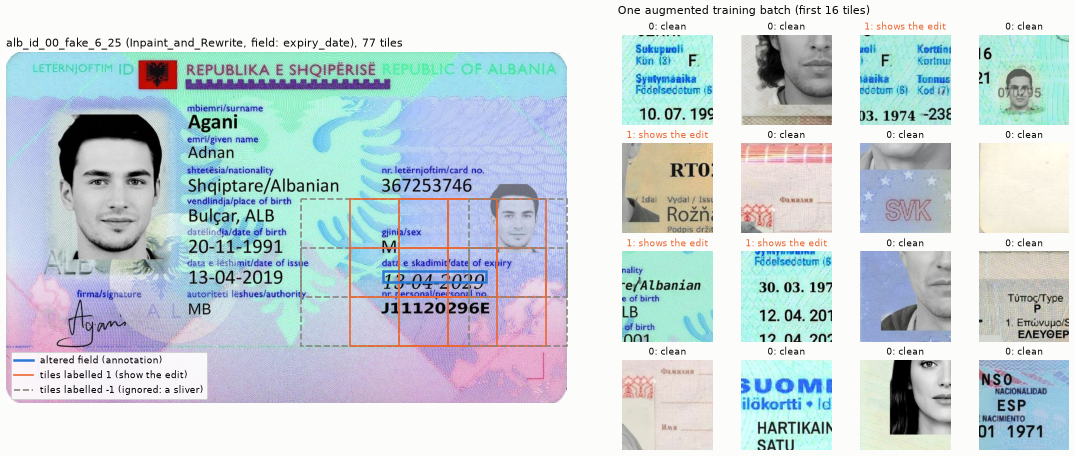

batch (32, 224, 224, 3), float32, pixel range 0-255, 5 of 32 tiles labelled 1


In [5]:
# Left: the tile labels of one forged training page. Right: one augmented training batch as the model sees it.
example = train_pages[train_pages["label"] == 1].sort_values("fake_name").iloc[0]
page_tiles = train_tiles[train_tiles["page"] == example.name]
fig = plt.figure(figsize=(18, 7.5), dpi=60, facecolor=SURFACE, layout="constrained")
left, right = fig.subfigures(1, 2, width_ratios=[1.25, 1])
ax = left.subplots()
with Image.open(ROOT / example["hires_path"]) as image:
    ax.imshow(image)
for row in page_tiles[page_tiles["label"] != 0].itertuples():
    color = ORANGE if row.label == 1 else MUTED
    ax.add_patch(Rectangle((row.x, row.y), TILE, TILE, fill=False, edgecolor=color, linewidth=2,
                           linestyle="-" if row.label == 1 else "--"))
ax.add_patch(Rectangle((example["edit_x"], example["edit_y"]), example["edit_w"], example["edit_h"],
                       fill=False, edgecolor=BLUE, linewidth=3))
ax.plot([], [], color=BLUE, linewidth=3, label="altered field (annotation)")
ax.plot([], [], color=ORANGE, linewidth=2, label="tiles labelled 1 (show the edit)")
ax.plot([], [], color=MUTED, linewidth=2, linestyle="--", label="tiles labelled -1 (ignored: a sliver)")
ax.legend(loc="lower left", fontsize=11, framealpha=0.9)
ax.set_title(f"{example['fake_name']} ({example['ctype']}, field: {example['altered_field']}), "
             f"{len(page_tiles)} tiles", loc="left", color=INK, fontsize=13)
ax.axis("off")

images, labels = next(iter(train_ds))
axes = right.subplots(4, 4)
for a, image, label in zip(axes.flat, images.numpy(), labels.numpy()):
    a.imshow(image.astype("uint8"))
    a.set_title("1: shows the edit" if label == 1 else "0: clean", fontsize=11, color=ORANGE if label == 1 else INK)
    a.axis("off")
right.suptitle("One augmented training batch (first 16 tiles)", x=0.02, ha="left", color=INK, fontsize=13)
fig.savefig(REPORT_DIR / "forgery_v3_tiles_check.png", dpi=70, facecolor=SURFACE)
plt.show()
print(f"batch {tuple(images.shape)}, {images.dtype.name}, pixel range {images.numpy().min():.0f}-{images.numpy().max():.0f}, "
      f"{int(labels.numpy().sum())} of {len(labels)} tiles labelled 1")

<!-- id: tiles_check -->
**Check of the labels and the input.** Left: on a forged training page the orange tiles (label 1) cover the altered
expiry date (blue box); the grey dashed tiles touch it only with a thin sliver and are ignored (label -1). Right: one
augmented training batch; 5 of its 32 tiles show an edit, and the pixels are float32 in 0-255, which is what
EfficientNet expects (it rescales internally).

## 3 · Training (same model and rules as v2)

**This run was resumed.** The first session (16 Nov, from 17:50) trained stage 1 (5 epochs) and stage-2 epochs
1-3. During stage-2 epoch 4 the GPU driver (tensorflow-metal) hung under memory pressure: no batch was processed
for over an hour. The hung process was stopped, and this session continues from the files the first one saved
(`RESUME_STAGE2_AT = 3` in the setup cell):
- stage 1 is not trained again; its log and best checkpoint are used as they are;
- stage 2 continues from its checkpoint after epoch 3. That file holds the weights, which layers are trainable
  and the optimizer's state (Adam's running averages after 2,868 steps). Epoch 3 was the best epoch so far
  (checked below), so this is the state the run would have had at the start of epoch 4;
- the callbacks count from the earlier best (`resume_best` in `models.training_callbacks`), so the checkpoint,
  early stopping and the learning-rate halving behave as if the run had never stopped.

The only difference from an uninterrupted run is which random clean tiles each remaining epoch draws.
Epoch times are measured only for the epochs trained in this session.

In [6]:
if RESUME_STAGE2_AT is None:
    model, backbone = models.build_forgery_detector(TILE)  # EfficientNetB0 (ImageNet) + sigmoid head, 224 px input
    models.compile_forgery_model(model, STAGE1["learning_rate"])  # Adam with clipnorm=1.0, PR-AUC + ROC-AUC
    print(f"EfficientNetB0 tile model: {model.count_params():,} parameters, "
          f"{int(sum(np.prod(w.shape) for w in model.trainable_weights)):,} trainable in stage 1 (the head)\n")
    callbacks_s1 = models.training_callbacks(MODEL_DIR / "forgery_v3_tiles_stage1.keras",
                                             REPORT_DIR / "forgery_v3_stage1_log.csv", STAGE1["patience"], MONITOR, "max")
    # shuffle=False: the tf.data pipeline already reshuffles pages and tiles every epoch.
    model.fit(train_ds, validation_data=val_ds, epochs=STAGE1["max_epochs"], class_weight=class_weight,
              callbacks=callbacks_s1, shuffle=False, verbose=2)
    s1_seconds = callbacks_s1[-1].seconds  # wall-clock seconds per epoch
else:
    s1_seconds = []  # stage 1 was trained in the first session (see the note above): nothing to train or time here


def timing(seconds):
    return f"{np.mean(seconds) / 60:.1f} min per epoch" if len(seconds) else "trained in the first session"


s1_log = pd.read_csv(REPORT_DIR / "forgery_v3_stage1_log.csv")  # one row per epoch (CSVLogger)
print(f"\nstage 1: {len(s1_log)} epochs ({timing(s1_seconds)}); best val tile PR-AUC {s1_log[MONITOR].max():.4f} "
      f"(epoch {s1_log[MONITOR].idxmax() + 1})")


stage 1: 5 epochs (trained in the first session); best val tile PR-AUC 0.2160 (epoch 3)


<!-- id: stage1 -->
**Stage 1 (only the new head trains)** was trained in the first session (5 epochs, about 7 min each by the log
files' timestamps) and is not re-run here. Best validation tile PR-AUC 0.216 at epoch 3 (v2: 0.214). With a frozen
ImageNet backbone the edit tiles are only weakly separated; random guessing would give 0.048.

In [7]:
STAGE2_CHECKPOINT, STAGE2_LOG = MODEL_DIR / "forgery_v3_tiles_stage2.keras", REPORT_DIR / "forgery_v3_stage2_log.csv"
if RESUME_STAGE2_AT is None:
    n_unfrozen = models.unfreeze_top_layers(backbone, STAGE2["unfreeze_layers"])
    models.compile_forgery_model(model, STAGE2["learning_rate"])  # re-compile after changing `trainable`
    print(f"unfrozen {n_unfrozen} of the top {STAGE2['unfreeze_layers']} backbone layers")
    resume_best = None
else:
    done = pd.read_csv(STAGE2_LOG)  # the stage-2 epochs of the first session
    # the checkpoint keeps the BEST epoch; it is the state to continue from only if the best is the last one
    assert len(done) == RESUME_STAGE2_AT and done[MONITOR].idxmax() == len(done) - 1, "cannot resume from here"
    resume_best = float(done[MONITOR].max())
    model = keras.models.load_model(STAGE2_CHECKPOINT)  # weights + trainable flags + optimizer state
    backbone = model.get_layer("efficientnetb0")
    print(f"resumed after stage-2 epoch {RESUME_STAGE2_AT}: val tile PR-AUC so far {resume_best:.4f}, learning rate "
          f"{float(model.optimizer.learning_rate):.0e}, optimizer steps so far {int(model.optimizer.iterations):,}")
n_bn_trainable = sum(l.trainable for l in backbone.layers if isinstance(l, keras.layers.BatchNormalization))
print(f"trainable backbone layers: {sum(l.trainable for l in backbone.layers)} (BatchNormalization: {n_bn_trainable}); "
      f"trainable parameters: {int(sum(np.prod(w.shape) for w in model.trainable_weights)):,}\n")
callbacks_s2 = models.training_callbacks(STAGE2_CHECKPOINT, STAGE2_LOG, STAGE2["patience"], MONITOR, "max",
                                         STAGE2["reduce_lr_patience"], resume_best=resume_best)
model.fit(train_ds, validation_data=val_ds, initial_epoch=RESUME_STAGE2_AT or 0, epochs=STAGE2["max_epochs"],
          class_weight=class_weight, callbacks=callbacks_s2, shuffle=False, verbose=2)
s2_seconds = callbacks_s2[-1].seconds  # only the epochs trained in this session
s2_log = pd.read_csv(STAGE2_LOG)
print(f"\nstage 2: {len(s2_log)} epochs, {len(s2_seconds)} of them in this session ({timing(s2_seconds)}); "
      f"best val tile PR-AUC {s2_log[MONITOR].max():.4f} (epoch {s2_log[MONITOR].idxmax() + 1})")

resumed after stage-2 epoch 3: val tile PR-AUC so far 0.7518, learning rate 3e-05, optimizer steps so far 2,868
trainable backbone layers: 60 (BatchNormalization: 0); trainable parameters: 3,055,901

Epoch 4/10


956/956 - 518s - 542ms/step - loss: 0.2364 - pr_auc: 0.8937 - roc_auc: 0.9654 - val_loss: 0.1236 - val_pr_auc: 0.8184 - val_roc_auc: 0.9613 - learning_rate: 3.0000e-05


Epoch 5/10


956/956 - 528s - 552ms/step - loss: 0.2042 - pr_auc: 0.9201 - roc_auc: 0.9744 - val_loss: 0.2132 - val_pr_auc: 0.8257 - val_roc_auc: 0.9540 - learning_rate: 3.0000e-05


Epoch 6/10


956/956 - 578s - 605ms/step - loss: 0.1953 - pr_auc: 0.9274 - roc_auc: 0.9766 - val_loss: 0.1185 - val_pr_auc: 0.8369 - val_roc_auc: 0.9582 - learning_rate: 3.0000e-05


... (8 outputs left out)


Epoch 10: ReduceLROnPlateau reducing learning rate to 7.499999810534064e-06.


956/956 - 489s - 512ms/step - loss: 0.1420 - pr_auc: 0.9602 - roc_auc: 0.9876 - val_loss: 0.1562 - val_pr_auc: 0.8552 - val_roc_auc: 0.9647 - learning_rate: 1.5000e-05


Restoring model weights from the end of the best epoch: 9.



stage 2: 10 epochs, 7 of them in this session (9.0 min per epoch); best val tile PR-AUC 0.8659 (epoch 9)


<!-- id: stage2 -->
**Stage 2 (top 75 backbone layers unfrozen), resumed after epoch 3.**
- The checkpoint loaded with the expected state: 60 trainable backbone layers, 0 trainable BatchNormalization
  layers (kept frozen, the Phase 3A rule), 3,055,901 trainable parameters, learning rate 3e-5 and 2,868 optimizer
  steps (3 epochs x 956 batches).
- Epochs 4-10 took 8.2-9.7 min each (mean 9.0; v2: 10.3).
- Validation tile PR-AUC rose from 0.752 to **0.866 at epoch 9**. Epoch 7 did not improve, so the learning rate was
  halved to 1.5e-5; epoch 10 did not improve either (halved again, but 10 epochs was the limit).
- Early stopping never triggered. The best epoch (9) is the saved checkpoint, and its weights were restored at the end.

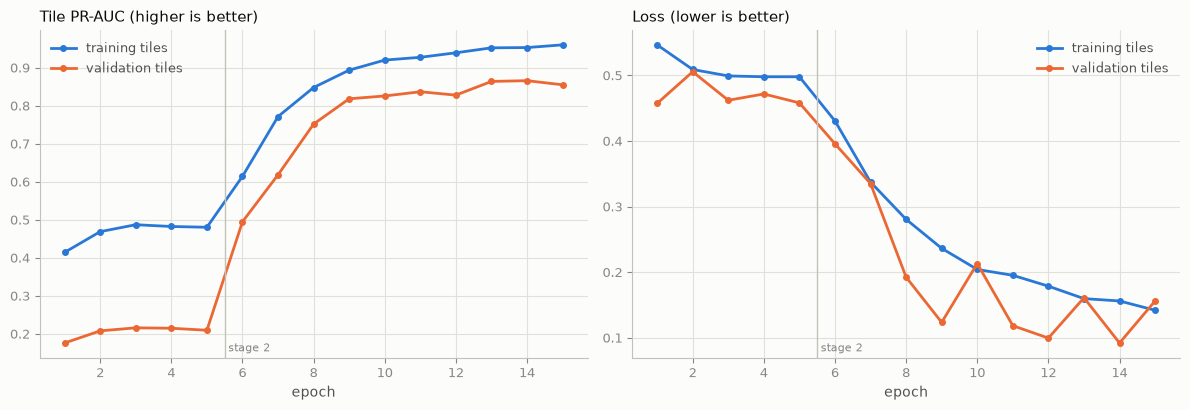

,loss,pr_auc,val_loss,val_pr_auc,val_roc_auc
1,0.5466,0.4144,0.4573,0.1761,0.8231
2,0.5090,0.4689,0.5056,0.2080,0.8349
3,0.4992,0.4871,0.4621,0.2160,0.8416
4,0.4979,0.4825,0.4717,0.2149,0.8387
5,0.4979,0.4805,0.4581,0.2096,0.8448
6,0.4307,0.6144,0.3958,0.4950,0.9083
7,0.3374,0.7716,0.3351,0.6185,0.9295
8,0.2806,0.8480,0.1925,0.7518,0.9433
9,0.2364,0.8937,0.1236,0.8184,0.9613
10,0.2042,0.9201,0.2132,0.8257,0.9540


In [8]:
logs = {name: pd.read_csv(REPORT_DIR / f"forgery_v3_{name}_log.csv") for name in ("stage1", "stage2")}
log = pd.concat(logs.values(), ignore_index=True)
epochs = np.arange(1, len(log) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), dpi=100, facecolor=SURFACE)
for ax, (train_col, val_col, title) in zip(axes, [("pr_auc", "val_pr_auc", "Tile PR-AUC (higher is better)"),
                                                  ("loss", "val_loss", "Loss (lower is better)")]):
    ax.plot(epochs, log[train_col], color=BLUE, linewidth=2, marker="o", markersize=4, label="training tiles")
    ax.plot(epochs, log[val_col], color=ORANGE, linewidth=2, marker="o", markersize=4, label="validation tiles")
    ax.axvline(len(logs["stage1"]) + 0.5, color=AXIS, linewidth=1)
    ax.text(len(logs["stage1"]) + 0.6, 0.02, "stage 2", transform=ax.get_xaxis_transform(), color=MUTED, fontsize=8)
    style(ax, title)
    ax.set_xlabel("epoch")
    ax.legend(frameon=False, labelcolor=INK_2, fontsize=9)
fig.tight_layout()
fig.savefig(REPORT_DIR / "forgery_v3_training_curves.png", dpi=150, facecolor=SURFACE)
plt.show()
display(log[["loss", "pr_auc", "val_loss", "val_pr_auc", "val_roc_auc"]].set_index(epochs).round(4))

<!-- id: curves -->
**Training curves.** Epochs 1-5 are stage 1 and 6-15 stage 2. Epochs 6-8 come from the first session and 9-15 from
the resumed one; there is no jump at the resume point.
- Stage 2 is where the model learns the edits: validation tile PR-AUC jumps from 0.21 to 0.50 in its first epoch
  and reaches 0.866.
- Training PR-AUC keeps rising (0.96) while validation levels off around 0.83-0.87, a mild overfitting gap. That is
  why the best checkpoint is kept, not the last one.
- The validation loss moves up and down (0.09-0.21) while PR-AUC is steadier. The loss also depends on how
  confident the scores are, PR-AUC only on their order, which is why PR-AUC is the selection metric.

## 4 · Validation: the stop rules first

In [9]:
# Score EVERY validation tile (including the ignored ones) with each saved checkpoint; scores keep table order.
checkpoints = {"stage 1": "forgery_v3_tiles_stage1.keras", "stage 2": "forgery_v3_tiles_stage2.keras"}
labelled = (val_tiles["label"] >= 0).to_numpy()
tile_scores, tile_ranking, loaded = {}, {}, {}
for name, file in checkpoints.items():
    if not (MODEL_DIR / file).exists():  # e.g. a stage stopped by TerminateOnNaN before its first checkpoint
        print(f"{name}: no checkpoint saved, skipped")
        continue
    loaded[name] = keras.models.load_model(MODEL_DIR / file)
    tile_scores[name] = tiles.score_tiles(loaded[name], val_pages, val_tiles)
    y_tile, s_tile = val_tiles["label"].to_numpy()[labelled], tile_scores[name][labelled]
    tile_ranking[name] = {"tile PR-AUC": average_precision_score(y_tile, s_tile),
                          "tile ROC-AUC": roc_auc_score(y_tile, s_tile)}
tile_ranking = pd.DataFrame(tile_ranking).T
display(tile_ranking.round(4))
choice = tile_ranking["tile PR-AUC"].idxmax()
detector = loaded[choice]
val_tiles["score"] = tile_scores[choice]
print(f"chosen checkpoint: {choice} ({checkpoints[choice]}); "
      f"random guessing would give tile PR-AUC {val_tiles.loc[labelled, 'label'].mean():.3f} (share of edit tiles)")

,tile PR-AUC,tile ROC-AUC
stage 1,0.2154,0.8409
stage 2,0.8685,0.9592


chosen checkpoint: stage 2 (forgery_v3_tiles_stage2.keras); random guessing would give tile PR-AUC 0.048 (share of edit tiles)


<!-- id: tile_choice -->
**Which checkpoint.** Re-scoring every labelled validation tile gives tile PR-AUC 0.869 (ROC-AUC 0.959) for stage 2
against 0.215 for stage 1, so the stage-2 checkpoint (epoch 9) is the detector. Keras reported 0.866 during
training: its AUC uses 200 fixed thresholds, while scikit-learn's average precision is exact. v2 had 0.874, so
removing the compression cue cost almost nothing at tile level.

In [10]:
y_doc = val_pages["label"].to_numpy()
page_score = {how: tiles.page_scores(val_tiles, how=how).reindex(range(len(val_pages))).to_numpy()
              for how in ("max", "top3")}
aggregation = pd.DataFrame({how: evaluation.ranking_scores(y_doc, s) for how, s in page_score.items()}).T
aggregation.index = ["highest tile (max)", "mean of top 3 tiles (top3)"]
display(aggregation.round(4))
AGGREGATION = max(page_score, key=lambda how: evaluation.ranking_scores(y_doc, page_score[how])["pr_auc"])
val_pages["score"] = page_score[AGGREGATION]
doc_ranking = evaluation.ranking_scores(y_doc, val_pages["score"])
print(f"page score = {AGGREGATION} (chosen on validation PR-AUC). Random guessing: PR-AUC {y_doc.mean():.3f}, ROC-AUC 0.5")

,pr_auc,roc_auc
highest tile (max),0.9632,0.9391
mean of top 3 tiles (top3),0.9629,0.9387


page score = max (chosen on validation PR-AUC). Random guessing: PR-AUC 0.544, ROC-AUC 0.5


<!-- id: aggregation -->
**Page score.** The rule set before training: mean of the top 3 tiles, unless validation prefers another option.
The highest tile scored PR-AUC 0.9632 against 0.9629 for the top-3 mean (ROC-AUC 0.9391 vs 0.9387), so the rule
picked the highest tile. The difference (0.0003) is a practical tie. Random guessing gives PR-AUC 0.544, the forged
share of the validation pages.

In [11]:
# THE STOP RULES. Position-matched negative control: forged pages' tiles that do not show the edit against
# genuine pages' tiles at the same position; 95 % intervals from resampling pages. The "far" version only keeps
# tiles at least 112 px from the edit (extra information; the rule uses all off-edit tiles).
control = evaluation.position_matched_control(val_tiles, val_pages, n_boot=N_BOOT)
control_far = evaluation.position_matched_control(val_tiles, val_pages, far_only=True, n_boot=N_BOOT)
hidden_auc = evaluation.edit_hidden_doc_auc(val_tiles, val_pages, how=AGGREGATION)
per_type = control.drop(index="all types")
worst_type = per_type["AUC"].idxmax()


def with_interval(table):
    return table.apply(lambda r: f"{r['AUC']:.3f} [{r['95% low']:.3f}, {r['95% high']:.3f}]", axis=1)


display(pd.DataFrame({"forged-page tiles": control["forged-page tiles"], "genuine tiles": control["genuine tiles"],
                      "AUC, off-edit tiles [95% interval]": with_interval(control),
                      "AUC, tiles >= 112 px from the edit": with_interval(control_far)}))
rules = pd.DataFrame({
    "value": [control.loc["all types", "AUC"], per_type["AUC"].max(), hidden_auc, doc_ranking["roc_auc"]],
    "limit": [f"<= {MAX_CONTROL_AUC}", f"<= {MAX_CONTROL_AUC_PER_TYPE}", f"<= {MAX_HIDDEN_AUC}", f">= {MIN_DOC_ROC_AUC}"],
    "pass": [control.loc["all types", "AUC"] <= MAX_CONTROL_AUC, per_type["AUC"].max() <= MAX_CONTROL_AUC_PER_TYPE,
             hidden_auc <= MAX_HIDDEN_AUC, doc_ranking["roc_auc"] >= MIN_DOC_ROC_AUC],
}, index=["position-matched control, all types", f"position-matched control, highest type ({worst_type})",
          "edit-hidden document ROC-AUC", "document ROC-AUC"])
display(rules.round(4))
PASSED = bool(rules["pass"].all())
pd.concat({"off-edit": control, "far": control_far}, axis=1).to_csv(REPORT_DIR / "forgery_v3_control_val.csv")
print("ALL STOP RULES PASS" if PASSED else "STOP RULE FAILED: " + ", ".join(rules.index[~rules["pass"]]) +
      " -> the model will be saved as forgery_detector_v3_rejected; report, do not tune")

,forged-page tiles,genuine tiles,"AUC, off-edit tiles [95% interval]","AUC, tiles >= 112 px from the edit"
all types,12993,12221,"0.491 [0.478, 0.504]","0.492 [0.477, 0.509]"
alb_id,948,1078,"0.457 [0.404, 0.504]","0.473 [0.402, 0.536]"
aze_passport,673,1144,"0.477 [0.430, 0.517]","0.479 [0.426, 0.535]"
esp_id,1039,1078,"0.451 [0.422, 0.476]","0.436 [0.401, 0.468]"
est_id,922,1078,"0.510 [0.469, 0.539]","0.515 [0.480, 0.548]"
fin_id,1270,1155,"0.477 [0.452, 0.504]","0.478 [0.446, 0.510]"
grc_passport,2024,1408,"0.510 [0.473, 0.551]","0.517 [0.472, 0.569]"
lva_passport,1544,1496,"0.514 [0.471, 0.554]","0.516 [0.469, 0.560]"
rus_internalpassport,1657,1320,"0.475 [0.448, 0.514]","0.476 [0.451, 0.513]"
srb_passport,1361,1309,"0.498 [0.462, 0.540]","0.495 [0.461, 0.544]"


,value,limit,pass
"position-matched control, all types",0.4908,<= 0.55,True
"position-matched control, highest type (lva_passport)",0.5138,<= 0.6,True
edit-hidden document ROC-AUC,0.4034,<= 0.58,True
document ROC-AUC,0.9391,>= 0.7,True


ALL STOP RULES PASS


<!-- id: stop_rules -->
**Stop rules: all three pass.**
1. **Position-matched control: 0.491 [0.478, 0.504]** for all types (limit 0.55). The highest type is lva_passport,
   0.514 [0.471, 0.554] (limit 0.60). Away from the edit, forged pages now look like genuine pages at the same
   place. In v2 this was 0.584 overall and 0.713 on est_id. Tiles at least 112 px from the edit give the same
   picture (0.492 overall).
2. **Edit tiles hidden: document ROC-AUC 0.403** (limit 0.58). Without their edit, forged pages are not recognised.
   The value is below 0.5 mainly because the hidden tiles are text around the altered field, and text scores
   higher than plain background: a forged page without those tiles has a lower best tile than a genuine page with them.
3. **Document ROC-AUC 0.939** (limit 0.70).

One detail: esp_id (0.451 [0.422, 0.476]) and alb_id (0.457 [0.404, 0.504]) lie *below* 0.5. Away from the edit, their
forged pages look slightly cleaner than genuine ones. That direction cannot help the model flag forgeries and it is
inside the per-type limit, but it shows that forged and genuine pages of these two types are not perfectly alike; we
did not trace the cause.

## 5 · Validation results

In [12]:
thresholds = {"recall >= 0.90": evaluation.threshold_for_recall(y_doc, val_pages["score"], 0.90),
              "F1-optimal": evaluation.f1_optimal_threshold(y_doc, val_pages["score"])}
threshold_table = pd.DataFrame(thresholds).T
threshold_table.to_csv(REPORT_DIR / "forgery_v3_thresholds_val.csv")
display(threshold_table.round(4))
display(pd.concat({rule: evaluation.confusion_at(y_doc, val_pages["score"], t["threshold"])
                   for rule, t in thresholds.items()}, axis=1))
threshold = thresholds["recall >= 0.90"]["threshold"]

,threshold,precision,recall,f1
recall >= 0.90,0.7290,0.8351,0.9050,NaN
F1-optimal,0.8574,0.9294,0.8827,0.9054


recall >= 0.90                         F1-optimal                 
        predicted genuine predicted forged predicted genuine predicted forged
genuine               118               32               138               12
forged                 17              162                21              158

<!-- id: thresholds -->
**Thresholds and confusion matrices** (validation: 150 genuine, 179 forged pages).
- **Recall >= 0.90** (threshold 0.729): 162 of 179 forged pages caught (recall 0.905), 32 of 150 genuine pages
  flagged, precision 0.835.
- **F1-optimal** (threshold 0.857): 158 caught (recall 0.883), 12 genuine flagged, precision 0.929, F1 0.905.

v2 had 5 false alarms at recall 0.91; v3 has 32. Part of v2's clean separation came from the compression cue. The
F1 threshold gives up 4 caught forgeries for 20 fewer false alarms. In the decision engine a flagged page goes to
manual review, so the choice is a cost trade-off for the bank. Both thresholds are chosen on validation and are
checked once on the test split.

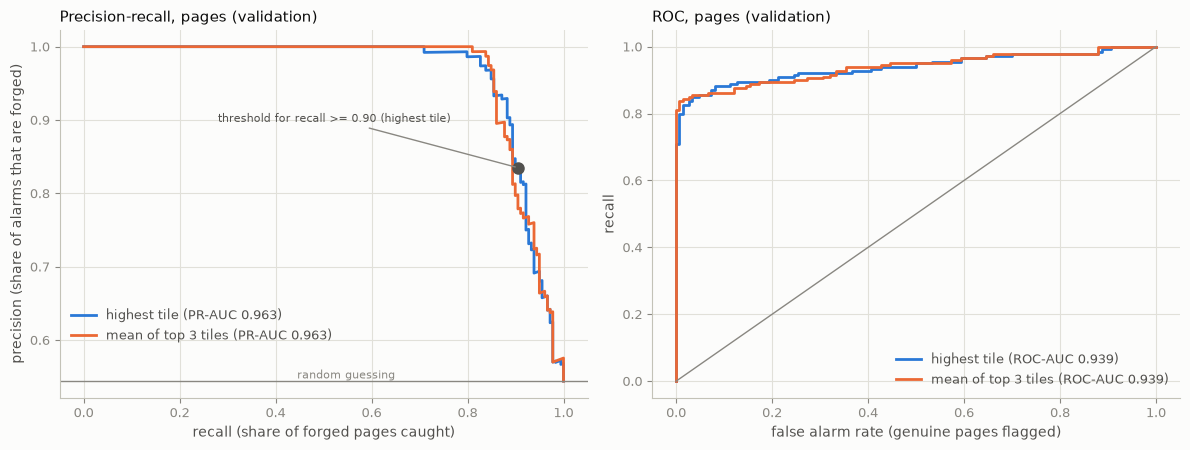

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), dpi=100, facecolor=SURFACE)
labels = {"max": "highest tile", "top3": "mean of top 3 tiles"}
for (how, s), color in zip(page_score.items(), (BLUE, ORANGE)):
    r = evaluation.ranking_scores(y_doc, s)
    precision, recall, _ = precision_recall_curve(y_doc, s)
    axes[0].plot(recall, precision, color=color, linewidth=2, label=f"{labels[how]} (PR-AUC {r['pr_auc']:.3f})")
    fpr, tpr, _ = roc_curve(y_doc, s)
    axes[1].plot(fpr, tpr, color=color, linewidth=2, label=f"{labels[how]} (ROC-AUC {r['roc_auc']:.3f})")
t = thresholds["recall >= 0.90"]
axes[0].plot(t["recall"], t["precision"], "o", color=INK_2, markersize=8)
# labels sit in empty parts of the plot (the curves run along the top and down the right edge)
axes[0].annotate(f"threshold for recall >= 0.90 ({labels[AGGREGATION]})", (t["recall"], t["precision"]),
                 xytext=(0.3, 0.75), textcoords="axes fraction", color=INK_2, fontsize=8,
                 arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 1})
axes[0].axhline(y_doc.mean(), color=MUTED, linewidth=1)
axes[0].text(0.45, y_doc.mean(), "random guessing", color=MUTED, fontsize=8, va="bottom",
             transform=axes[0].get_yaxis_transform())
axes[1].plot([0, 1], [0, 1], color=MUTED, linewidth=1)
style(axes[0], "Precision-recall, pages (validation)")
style(axes[1], "ROC, pages (validation)")
axes[0].set(xlabel="recall (share of forged pages caught)", ylabel="precision (share of alarms that are forged)")
axes[1].set(xlabel="false alarm rate (genuine pages flagged)", ylabel="recall")
axes[0].legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="lower left", bbox_to_anchor=(0.0, 0.12))
axes[1].legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="lower right")
fig.tight_layout()
fig.savefig(REPORT_DIR / "forgery_v3_pr_roc_val.png", dpi=150, facecolor=SURFACE)
plt.show()

<!-- id: curves_pr -->
**PR and ROC curves** (blue = highest tile, the chosen page score; orange = top-3 mean, almost identical).
Precision stays close to 1.0 up to about 80 % recall: the most confident alarms are all real forgeries. Beyond
85 % recall it falls quickly, because the last forgeries (mostly Crop_and_Replace) score like genuine pages. The
dot marks the recall >= 0.90 threshold (precision 0.835).

In [14]:
breakdowns = {}
for by in ("ctype", "doc_type", "altered_field"):
    table = evaluation.breakdown(val_pages, by, threshold)
    if by in ("ctype", "altered_field"):  # forged pages only: recall is the meaningful number
        table = table[["forged", "recall"]]
    breakdowns[by] = table
    table.to_csv(REPORT_DIR / f"forgery_v3_breakdown_{by}_val.csv")
print(f"All breakdowns at the recall >= 0.90 threshold ({threshold:.4f}), validation pages.")
for by in ("ctype", "doc_type"):
    display(breakdowns[by].round(3))
display(breakdowns["altered_field"].sort_values("forged", ascending=False).round(3))

All breakdowns at the recall >= 0.90 threshold (0.7290), validation pages.


,forged,recall
ctype,,
Crop_and_Replace,22.0,0.318
Inpaint_and_Rewrite,157.0,0.987


,images,forged,recall,false_alarm,precision,pr_auc
doc_type,,,,,,
alb_id,28.0,14.0,1.000,0.000,1.000,1.000
aze_passport,22.0,9.0,0.889,0.231,0.727,0.960
esp_id,29.0,15.0,1.000,0.286,0.789,0.996
est_id,27.0,13.0,1.000,0.643,0.591,1.000
fin_id,33.0,18.0,0.944,0.267,0.810,0.952
grc_passport,42.0,26.0,0.808,0.062,0.955,0.960
lva_passport,37.0,20.0,0.850,0.176,0.850,0.941
rus_internalpassport,36.0,21.0,0.952,0.200,0.870,0.992
srb_passport,37.0,20.0,0.750,0.176,0.833,0.907


,forged,recall
altered_field,,
gender,20.0,0.800
name,16.0,0.875
expiry_date,15.0,0.867
surname,14.0,1.000
birth_place,14.0,0.929
number,10.0,0.900
height,9.0,0.778
issue_date,8.0,1.000
birth_date,8.0,0.875


<!-- id: breakdown -->
**Where it works and where it fails** (at the recall >= 0.90 threshold).
- **By forgery type:** Inpaint_and_Rewrite 155 of 157 caught (0.987); Crop_and_Replace only 7 of 22 (0.318; v2:
  9 of 22). Pasted real printed text leaves almost no pixel trace; this needs the planned field-consistency rule
  (Phases 5/7).
- **By document type:** recall is 1.0 on alb_id, esp_id and est_id, and lowest on srb_passport (0.75) and
  grc_passport (0.81), the two types with the smallest fields (median about 20 px).
- **False alarms concentrate on est_id:** 9 of its 14 genuine pages are flagged (0.643), then esp_id (4 of 14) and
  fin_id (4 of 15). The position-matched control on est_id is 0.51, so this is not a page-level shortcut: some
  regions of est_id pages score high on genuine and forged pages alike. It is the first place to look if precision
  must improve.
- **By altered field:** the groups are small (1-20 pages), and no field is systematically missed; the lowest are
  mrz_line0 (4 of 6) and birth_place_line0 (2 of 3).

In [15]:
def localisation_summary(tile_table, page_table, threshold):
    """Is the highest-scoring tile of each forged page on the edit? Against a random tile of the same page."""
    top = tile_table.loc[tile_table.groupby("page")["score"].idxmax()].set_index("page")
    forged_top = top[page_table["label"].to_numpy()[top.index] == 1]
    detected = page_table.loc[forged_top.index, "score"].to_numpy() >= threshold
    on_forged_page = page_table["label"].to_numpy()[tile_table["page"].to_numpy()] == 1
    chance = tile_table[on_forged_page].groupby("page")["overlaps_edit"].mean()
    return pd.Series({"forged pages": len(forged_top),
                      "top tile touches the edit": forged_top["overlaps_edit"].mean(),
                      "same, detected pages only": forged_top.loc[detected, "overlaps_edit"].mean(),
                      "detected pages": int(detected.sum()),
                      "random tile touches the edit (baseline)": chance.mean()})


localisation = localisation_summary(val_tiles, val_pages, threshold)
localisation.to_csv(REPORT_DIR / "forgery_v3_localisation_val.csv", header=["value"])
display(localisation.to_frame("value").round(3))

,value
forged pages,179.000
top tile touches the edit,0.933
"same, detected pages only",0.988
detected pages,162.000
random tile touches the edit (baseline),0.110


<!-- id: localisation -->
**Does the top tile sit on the edit?** For 93.3 % of forged pages (167 of 179) the highest-scoring tile touches the
altered field, and for 98.8 % of the 162 detected pages (160). A randomly chosen tile would touch it 11 % of the
time. When v3 flags a page, it is almost always because of the edited field (v2: 93.9 %).

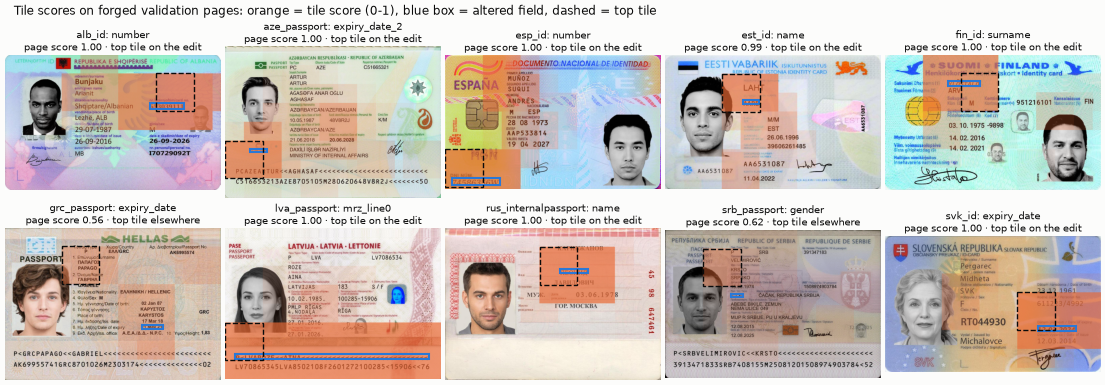

In [16]:
examples = val_pages[val_pages["label"] == 1].sort_values("fake_name").groupby("doc_type").head(1).sort_values("doc_type")
heat_cmap = LinearSegmentedColormap.from_list("heat", [(0.92, 0.41, 0.20, 0.0), (0.92, 0.41, 0.20, 0.7)])
fig, axes = plt.subplots(2, 5, figsize=(22, 7.6), dpi=50, facecolor=SURFACE, layout="constrained")
for ax in axes.flat:
    ax.axis("off")
for ax, (page, row) in zip(axes.flat, examples.iterrows()):
    page_tiles = val_tiles[val_tiles["page"] == page]
    heat = tiles.tile_heatmap(row.hires_width, row.hires_height, page_tiles[["x", "y"]].to_numpy(),
                              page_tiles["score"].to_numpy())
    with Image.open(ROOT / row.hires_path) as image:
        ax.imshow(image)
    ax.imshow(heat, cmap=heat_cmap, vmin=0, vmax=1)
    ax.add_patch(Rectangle((row.edit_x, row.edit_y), row.edit_w, row.edit_h, fill=False, edgecolor=BLUE, linewidth=3))
    top = page_tiles.loc[page_tiles["score"].idxmax()]
    ax.add_patch(Rectangle((top.x, top.y), TILE, TILE, fill=False, edgecolor=INK, linewidth=2, linestyle="--"))
    hit = "top tile on the edit" if top.overlaps_edit else "top tile elsewhere"
    ax.set_title(f"{row.doc_type}: {row.altered_field}\npage score {row.score:.2f} · {hit}", fontsize=14, color=INK)
fig.suptitle("Tile scores on forged validation pages: orange = tile score (0-1), blue box = altered field, "
             "dashed = top tile", x=0.01, ha="left", color=INK, fontsize=17)
fig.savefig(REPORT_DIR / "forgery_v3_heatmaps_val.png", dpi=70, facecolor=SURFACE)
plt.show()

<!-- id: heatmaps -->
**Heatmaps** (one forged validation page per document type; orange = tile score, blue box = altered field,
dashed = top tile).
- On 8 of the 10 pages the hottest tile is on the edit, with a page score of about 1.0.
- The two misses are grc_passport (expiry date, score 0.56) and srb_passport (gender, score 0.62). Both are below
  the 0.729 threshold, so both pages are missed; their fields are among the smallest.
- Photos, backgrounds and most of the text stay pale.

In [17]:
# Round-trip check: does v3 care about a page's compression HISTORY? Score the SAME genuine validation pages as
# stored in the v2 cache (their original history: quality 92, no extra quality-75 save) and compare.
other_history = tiles.score_genuine_from_cache(detector, val_pages, val_tiles, config.HIRES_DIR)
history_v3 = evaluation.compression_history_check(val_tiles, val_pages, other_history, threshold, how=AGGREGATION,
                                                  names=("as trained (extra q75 save)", "original q92 history"))
history_v3.to_csv(REPORT_DIR / "forgery_v3_history_check_val.csv")


def show_history(table):
    """Counts as whole numbers, everything else with 4 decimals."""
    return table.apply(lambda row: row.map(lambda v: str(int(v)) if row.name in ("false alarms at threshold",
                                                                                   "genuine pages") else f"{v:.4f}"),
                       axis=1)


display(show_history(history_v3))

,as trained (extra q75 save),original q92 history
position-matched control AUC,0.4908,0.4530
edit-hidden document ROC-AUC,0.4034,0.3536
document ROC-AUC,0.9391,0.9247
document PR-AUC,0.9632,0.9532
false alarms at threshold,32,48
genuine pages,150,150
mean genuine tile score,0.0634,0.0729


<!-- id: history -->
**Compression-history check.** The same genuine validation pages are scored again from the v2 cache, with their
original q92 history and without the extra q75 save. If v3 ignored compression history, both columns would match.

They do not. Without the extra save, genuine pages look a little *more* suspicious: the mean tile score goes from
0.063 to 0.073, false alarms from 32 to 48, and document ROC-AUC from 0.939 to 0.925. This is the opposite
direction to v2. It no longer helps on this data, because every training and validation page now has the same
history.

But it means the model is sensitive to how a file was compressed. In the pipeline, every uploaded page must get the
same preprocessing (q75 save at original size, resize, q75 save; stated in `forgery_detector.json`). The threshold
must also be re-checked on real uploads, whose compression history will differ again.

## 6 · v2 against v3

In [18]:
# v2 = the same code on the v2 cache (genuine pages WITHOUT the extra save), with the saved v2 model. Everything
# is recomputed here with the same functions, so both columns are measured the same way.
v2_model = keras.models.load_model(V2_MODEL)
v2_pages = val_pages.drop(columns="score").assign(
    hires_path=[data.cache_path_for(p, config.HIRES_DIR) for p in val_pages["image_path"]])
v2_tiles = val_tiles.assign(score=tiles.score_tiles(v2_model, v2_pages, val_tiles))
v2_pages["score"] = tiles.page_scores(v2_tiles, how="top3").reindex(range(len(v2_pages))).to_numpy()  # v2 used top3
v2_threshold = evaluation.threshold_for_recall(y_doc, v2_pages["score"], 0.90)["threshold"]
v2_control = evaluation.position_matched_control(v2_tiles, v2_pages, n_boot=N_BOOT)
v2_history = evaluation.compression_history_check(
    v2_tiles, v2_pages, tiles.score_genuine_from_cache(v2_model, v2_pages, val_tiles, config.HIRES_EQ_DIR),
    v2_threshold, how="top3", names=("as trained (q92 history)", "with the extra q75 save"))
v2_metrics = json.loads(V2_METRICS.read_text())


def summary(tile_table, page_table, control_table, history, threshold, epochs, minutes):
    y_tile = tile_table.loc[labelled, "label"]
    flagged = page_table["score"] >= threshold
    ctype = evaluation.breakdown(page_table, "ctype", threshold)["recall"]
    per_type_auc = control_table.drop(index="all types")["AUC"]
    return {
        "document PR-AUC": evaluation.ranking_scores(y_doc, page_table["score"])["pr_auc"],
        "document ROC-AUC": evaluation.ranking_scores(y_doc, page_table["score"])["roc_auc"],
        "tile PR-AUC": average_precision_score(y_tile, tile_table.loc[labelled, "score"]),
        "threshold (recall >= 0.90)": threshold,
        "precision at that threshold": page_table.loc[flagged, "label"].mean(),
        "recall at that threshold": flagged[y_doc == 1].mean(),
        "false alarms (of the genuine pages)": int(flagged[y_doc == 0].sum()),
        "position-matched control, all types": control_table.loc["all types", "AUC"],
        "  95% interval": f"[{control_table.loc['all types', '95% low']:.3f}, {control_table.loc['all types', '95% high']:.3f}]",
        "position-matched control, highest type": f"{per_type_auc.max():.3f} ({per_type_auc.idxmax()})",
        "edit-hidden document ROC-AUC": evaluation.edit_hidden_doc_auc(tile_table, page_table, how="top3"),
        "top tile on the edit (forged pages)": localisation_summary(tile_table, page_table, threshold)["top tile touches the edit"],
        "recall, Inpaint_and_Rewrite": ctype.get("Inpaint_and_Rewrite"),
        "recall, Crop_and_Replace": ctype.get("Crop_and_Replace"),
        "false alarms with the other compression history": int(history.iloc[:, 1]["false alarms at threshold"]),
        "document ROC-AUC with the other compression history": history.iloc[:, 1]["document ROC-AUC"],
        "epochs (stage 1 + stage 2)": epochs,
        "minutes per epoch, stage 2": minutes,
    }


comparison = pd.DataFrame({
    "v2 (compression cue)": summary(v2_tiles, v2_pages, v2_control, v2_history, v2_threshold,
                                    f"{v2_metrics['epochs']['stage 1']} + {v2_metrics['epochs']['stage 2']}",
                                    v2_metrics["mean_epoch_minutes"]["stage 2"]),
    "v3 (equal history)": summary(val_tiles, val_pages, control, history_v3, threshold,
                                  f"{len(s1_log)} + {len(s2_log)}",  # epochs from the logs (both sessions)
                                  round(float(np.mean(s2_seconds)) / 60, 2)),  # timed epochs (this session)
})
comparison.to_csv(REPORT_DIR / "forgery_v3_vs_v2_val.csv")
display(comparison.map(lambda v: f"{v:.3f}" if isinstance(v, float) else v))
print("v2's history check (its genuine pages given the extra q75 save):")
display(show_history(v2_history))

,v2 (compression cue),v3 (equal history)
document PR-AUC,0.983,0.963
document ROC-AUC,0.974,0.939
tile PR-AUC,0.874,0.868
threshold (recall >= 0.90),0.741,0.729
precision at that threshold,0.970,0.835
recall at that threshold,0.911,0.905
false alarms (of the genuine pages),5,32
"position-matched control, all types",0.584,0.491
95% interval,"[0.564, 0.605]","[0.478, 0.504]"
"position-matched control, highest type",0.713 (est_id),0.514 (lva_passport)


v2's history check (its genuine pages given the extra q75 save):


,as trained (q92 history),with the extra q75 save
position-matched control AUC,0.5839,0.4950
edit-hidden document ROC-AUC,0.5830,0.4023
document ROC-AUC,0.9737,0.9531
document PR-AUC,0.9825,0.9713
false alarms at threshold,5,11
genuine pages,150,150
mean genuine tile score,0.0546,0.0702


<!-- id: comparison -->
**v2 against v3** (validation, same pages). v3 trades some accuracy for honesty.
- Document PR-AUC 0.983 to 0.963 and ROC-AUC 0.974 to 0.939. Tile PR-AUC is almost unchanged (0.874 to 0.868),
  and the top tile still lands on the edit (93.9 % to 93.3 %).
- The cost shows in false alarms at recall 0.90: 5 to 32 genuine pages.
- In return, the shortcut checks are clean: the position-matched control falls from 0.584 to 0.491 (highest type
  0.713 to 0.514), and the edit-hidden ROC-AUC from 0.583 to 0.386. v2 would have failed that rule (limit 0.58).
- Crop_and_Replace stays weak (9 to 7 of 22 caught).

The edit-hidden row uses the top-3 page score for both models; with v3's own page score (highest tile) it is 0.403
(section 4).

The second table is v2's own history check: giving its genuine pages the extra save raised v2's false alarms from 5
to 11. v3 moves the other way (32 to 48) when the extra save is *removed*.

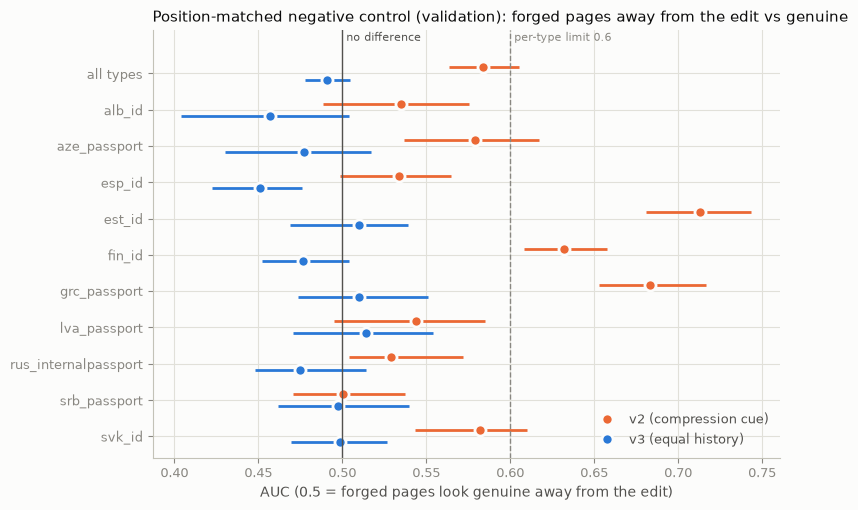

In [19]:
# Position-matched control per document type, v2 against v3 (dots = AUC, bars = 95 % interval).
names = ["all types"] + sorted(per_type.index)
fig, ax = plt.subplots(figsize=(8, 5.2), dpi=100, facecolor=SURFACE)
for offset, (label, table, color) in zip((-0.17, 0.17), (("v2 (compression cue)", v2_control, ORANGE),
                                                       ("v3 (equal history)", control, BLUE))):
    rows = table.reindex(names)
    y = np.arange(len(names)) + offset
    ax.hlines(y, rows["95% low"], rows["95% high"], color=color, linewidth=2)
    ax.plot(rows["AUC"], y, "o", color=color, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2, label=label)
ax.axvline(0.5, color=INK_2, linewidth=1)
ax.axvline(MAX_CONTROL_AUC_PER_TYPE, color=MUTED, linewidth=1, linestyle="--")
ax.text(0.5, -0.9, " no difference", color=INK_2, fontsize=8)
ax.text(MAX_CONTROL_AUC_PER_TYPE, -0.9, f" per-type limit {MAX_CONTROL_AUC_PER_TYPE}", color=MUTED, fontsize=8)
ax.set_yticks(np.arange(len(names)), names)
ax.set_ylim(len(names) - 0.4, -1.2)
style(ax, "Position-matched negative control (validation): forged pages away from the edit vs genuine")
ax.set_xlabel("AUC (0.5 = forged pages look genuine away from the edit)")
ax.legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="lower right")
fig.tight_layout()
fig.savefig(REPORT_DIR / "forgery_v3_vs_v2_control.png", dpi=150, facecolor=SURFACE)
plt.show()

<!-- id: comparison_plot -->
**Forest plot** (dot = AUC, bar = 95 % interval; orange v2, blue v3). v2 sits right of 0.5 for most types and
furthest on three enlarged types: est_id 0.71, grc_passport 0.68 and fin_id 0.63. That is the compression shortcut.
Every v3 interval reaches 0.5 except esp_id (slightly below, see section 4), and all stay well left of the 0.60
limit. The saved PNG in reports/ cuts off the right end of the title; the figure above shows it in full.

## 7 · Saving the model

In [20]:
name = "forgery_detector" if PASSED else "forgery_detector_v3_rejected"  # a failed model never gets the pipeline name
shutil.copy(MODEL_DIR / checkpoints[choice], MODEL_DIR / f"{name}.keras")
detector_info = {
    "version": "v3: tiles on compression-equalised hi-res templates",
    "status": "passed all three validation stop rules" if PASSED else
              "REJECTED: failed " + ", ".join(rules.index[~rules["pass"]]),
    "checkpoint": checkpoints[choice],
    "page_preprocessing": f"RGB; JPEG quality {GENUINE_PRE_QUALITY} save at the ORIGINAL size; resize so the longest side "
                          f"is exactly {LONGEST} px (Lanczos, small pages enlarged); JPEG quality {QUALITY} save; decode "
                          "(data.resize_to_cache with pre_quality, enlarge=True). Training applied the first save to "
                          "genuine pages only, because forged pages already had it; for new uploads apply it to every page.",
    "tile_size": TILE,
    "stride": STRIDE,
    "grid": "starts 0, stride, 2*stride, ... plus one last tile flush with the right/bottom edge (no padding)",
    "tile_input": "float32 pixels 0-255 (EfficientNet rescales internally; do not divide by 255)",
    "tile_output": "sigmoid probability that the tile shows an edited field",
    "aggregation": {"max": "page score = highest tile score",
                    "top3": "page score = mean of the 3 highest tile scores"}[AGGREGATION],
    "decision_rule": "forged if page score >= threshold",
    "thresholds": {"recall_0.90": {k: round(float(v), 4) for k, v in thresholds["recall >= 0.90"].items()},
                   "f1_optimal": {k: round(float(v), 4) for k, v in thresholds["F1-optimal"].items()}},
    "scope": "trained and validated on SIDTD templates (flat scans) only; not validated on photos or video frames. "
             "Crop_and_Replace edits (pasted real text) are mostly missed: combine with field-consistency rules.",
    "val": {"doc_pr_auc": round(doc_ranking["pr_auc"], 4), "doc_roc_auc": round(doc_ranking["roc_auc"], 4),
            "tile_pr_auc": round(float(tile_ranking.loc[choice, "tile PR-AUC"]), 4),
            "position_matched_control_auc": round(float(control.loc["all types", "AUC"]), 4),
            "position_matched_control_auc_highest_type": {worst_type: round(float(per_type["AUC"].max()), 4)},
            "edit_hidden_doc_roc_auc": round(hidden_auc, 4)},
    "notes": "thresholds were chosen on validation and must be re-checked once on the test split",
}
(MODEL_DIR / f"{name}.json").write_text(json.dumps(detector_info, indent=2))
print(f"saved models/{name}.keras and models/{name}.json")
print(json.dumps(detector_info, indent=2))

saved models/forgery_detector.keras and models/forgery_detector.json
{
  "version": "v3: tiles on compression-equalised hi-res templates",
  "status": "passed all three validation stop rules",
  "checkpoint": "forgery_v3_tiles_stage2.keras",
  "page_preprocessing": "RGB; JPEG quality 75 save at the ORIGINAL size; resize so the longest side is exactly 1280 px (Lanczos, small pages enlarged); JPEG quality 75 save; decode (data.resize_to_cache with pre_quality, enlarge=True). Training applied the first save to genuine pages only, because forged pages already had it; for new uploads apply it to every page.",
  "tile_size": 224,
  "stride": 112,
  "grid": "starts 0, stride, 2*stride, ... plus one last tile flush with the right/bottom edge (no padding)",
  "tile_input": "float32 pixels 0-255 (EfficientNet rescales internally; do not divide by 255)",
  "tile_output": "sigmoid probability that the tile shows an edited field",
  "aggregation": "page score = highest tile score",
  "decision_rule

<!-- id: saved -->
**Saved.** All three stop rules passed, so the stage-2 checkpoint is saved under the pipeline name
`models/forgery_detector.keras`. `forgery_detector.json` describes the preprocessing, the tiling, the page score
(highest tile), both thresholds and the scope (templates only; Crop_and_Replace mostly missed). v2 stays as
`forgery_detector_v2_compression_cue.keras` for comparison only. The thresholds are validation choices, and the
single test run will check them.

In [21]:
seconds = {"stage 1": s1_seconds, "stage 2": s2_seconds}
metrics = {
    "split": "validation (test not used)",
    "pages": {s: len(p) for s, p in split_pages.items()},
    "tiles": counts.drop(columns="tiles per page").to_dict(orient="index"),
    "tile_ranking": tile_ranking.round(4).to_dict(orient="index"),
    "checkpoint": choice,
    "aggregation": AGGREGATION,
    "stop_rules": {"passed": PASSED, **{k: {"value": round(float(r["value"]), 4), "limit": r["limit"], "pass": bool(r["pass"])}
                                        for k, r in rules.iterrows()}},
    "position_matched_control": control.round(4).to_dict(orient="index"),
    "position_matched_control_far": control_far.round(4).to_dict(orient="index"),
    "doc_ranking": {k: round(v, 4) for k, v in doc_ranking.items()},
    "thresholds": {rule: {k: round(float(v), 4) for k, v in t.items()} for rule, t in thresholds.items()},
    "localisation": localisation.round(4).to_dict(),
    "compression_history_check": history_v3.round(4).to_dict(),
    "epochs": {"stage 1": len(s1_log), "stage 2": len(s2_log)},
    "mean_epoch_minutes": {k: round(float(np.mean(v)) / 60, 2) if len(v) else None for k, v in seconds.items()},
    "epochs_timed_in_this_session": {k: len(v) for k, v in seconds.items()},
    "resumed": None if RESUME_STAGE2_AT is None else {
        "stage 2 epochs from the first session": RESUME_STAGE2_AT,
        "reason": "tensorflow-metal GPU hang during stage-2 epoch 4 (memory pressure); continued from the "
                  "stage-2 checkpoint (weights + optimizer state) with resume_best callbacks"},
    "peak_memory_gb": round(peak_memory_gb(), 2),  # this session
}
(REPORT_DIR / "forgery_v3_metrics_val.json").write_text(json.dumps(metrics, indent=2, default=str))
print(json.dumps({k: metrics[k] for k in ("epochs", "mean_epoch_minutes", "peak_memory_gb")}, indent=2))
print(f"swap in use now: {swap_used_gb():.1f} GB | notebook run time: {(time.perf_counter() - notebook_start) / 60:.1f} min")
for path in sorted(REPORT_DIR.glob("forgery_v3_*")):
    print(f"  {path.relative_to(ROOT) if path.is_relative_to(ROOT) else path}")

{
  "epochs": {
    "stage 1": 5,
    "stage 2": 10
  },
  "mean_epoch_minutes": {
    "stage 1": null,
    "stage 2": 8.99
  },
  "peak_memory_gb": 14.0
}
swap in use now: 20.5 GB | notebook run time: 74.3 min
  reports/phase3/forgery_v3_breakdown_altered_field_val.csv
  reports/phase3/forgery_v3_breakdown_ctype_val.csv
  reports/phase3/forgery_v3_breakdown_doc_type_val.csv
  reports/phase3/forgery_v3_control_val.csv
  reports/phase3/forgery_v3_heatmaps_val.png
  reports/phase3/forgery_v3_history_check_val.csv
  reports/phase3/forgery_v3_localisation_val.csv
  reports/phase3/forgery_v3_metrics_val.json
  reports/phase3/forgery_v3_pr_roc_val.png
  reports/phase3/forgery_v3_stage1_log.csv
  reports/phase3/forgery_v3_stage2_log.csv
  reports/phase3/forgery_v3_thresholds_val.csv
  reports/phase3/forgery_v3_tiles_check.png
  reports/phase3/forgery_v3_training_curves.png
  reports/phase3/forgery_v3_vs_v2_control.png
  reports/phase3/forgery_v3_vs_v2_val.csv


<!-- id: summary -->
**Run summary.**
- Stage 1: 5 epochs in the first session (about 7 min each).
- Stage 2: 10 epochs. Epochs 1-3 ran in the first session (about 9.5 min each, from the log files' timestamps) and
  epochs 4-10 in this one (9.0 min each; v2: 10.3).
- Peak memory of this session: 14.0 GB (v2: 12.0). The notebook ran for 74 min.
- Every result file listed above is validation-only; no test page was scored.

To run this notebook again from scratch, set `RESUME_STAGE2_AT = None` in the setup cell (the stage-2 log now holds
10 epochs, so resuming at 3 would stop at the check).